<a href="https://www.kaggle.com/code/nicapotato/us-vehicle-owner-complaints?scriptVersionId=364868019" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Complaint Exploration — US Vehicle Owner Complaints, 2010–2025
_Component rows are mentions; the vehicle total is the complaint count_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [iqbaltaherom/us-vehicle-owner-complaints-by-model-2010-2025](https://www.kaggle.com/datasets/iqbaltaherom/us-vehicle-owner-complaints-by-model-2010-2025)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [The Vehicle, Not the Component Row](#Vehicles)** <br>
**5. [Which Components Are Named](#Components)** <br>
**6. [Model Year and Make](#Year)** <br>
**7. [What Moves the Complaint Count](#Model)** <br>
**8. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
The CSV is a component rollup of NHTSA owner complaints for model years 2010–2025: 90,254 rows, one per make × model × model year × component. `complaints` is how many complaints named that component. `year_total` is the vehicle's complaint count, repeated on every component row of that vehicle.

Those two numbers answer different questions. Summing `complaints` double-counts a complaint that names more than one part. Summing `year_total` once per vehicle is the complaint census: 4,087 vehicles and 625,987 complaints. A highlight JSON of the most-complained vehicles is checked against that vehicle table.

Three component labels are blank. They stay blank and drop out of component charts. `Unknown or other` is a real residual label and stays in the component ranking.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import json
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` tests a crosstab and rank correlations; `sklearn` fits one linear model on a hold-out split. `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
CSV_BASENAME = "nhtsa-complaints-by-model-2010-2025.csv"
JSON_BASENAME = "most-complained-2026-q3.json"
KAGGLE_SLUG = "iqbaltaherom/us-vehicle-owner-complaints-by-model-2010-2025"
KEYS = ["make", "model", "model_year"]
EXPECTED = ["make", "model", "model_year", "component", "complaints", "year_total"]


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        hits = sorted(kaggle_root.rglob(basename))
        assert hits, f"no {basename} under {kaggle_root}"
        return hits[0]
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    root = Path(kagglehub.dataset_download(slug))
    hits = sorted(root.rglob(basename))
    assert hits, f"expected {basename} under {root}"
    return hits[0]


csv_path = resolve_file(CSV_BASENAME)
print("CSV:", csv_path)
df = pd.read_csv(csv_path, low_memory=False)
missing = set(EXPECTED) - set(df.columns)
assert not missing, sorted(missing)
assert df.shape == (90254, 6), df.shape
assert int(df["component"].isna().sum()) == 3
assert int(df.groupby(KEYS)["year_total"].nunique().max()) == 1
assert int(df["complaints"].sum()) == 886141

vehicles = (
    df.groupby(KEYS, as_index=False)
    .agg(complaints=("year_total", "first"), component_rows=("component", "size"))
)
assert len(vehicles) == 4087, len(vehicles)
assert int(vehicles["complaints"].sum()) == 625987

highlight = json.loads(resolve_file(JSON_BASENAME).read_text())
top_json = highlight["rows"][0]
top_csv = vehicles.nlargest(1, "complaints").iloc[0]
assert top_json["make"] == top_csv["make"]
assert top_json["model"] == top_csv["model"]
assert int(top_json["model_year"]) == int(top_csv["model_year"])
assert int(top_json["complaints"]) == int(top_csv["complaints"])

print("Dataframe Dimension: {} Rows, {} Columns".format(*df.shape))
print(
    f"Vehicles: {len(vehicles):,} | Makes: {vehicles['make'].nunique()} | "
    f"Model years: {vehicles['model_year'].min()}–{vehicles['model_year'].max()}"
)
print(f"Complaint census (one year_total per vehicle): {int(vehicles['complaints'].sum()):,}")
print(f"Component-mention sum: {int(df['complaints'].sum()):,}")
print(f"Mentions per complaint: {df['complaints'].sum() / vehicles['complaints'].sum():.3f}")
print("Null components:", int(df["component"].isna().sum()))
display(df.dtypes.to_frame("dtype"))
display(df.sample(5, random_state=7))

CSV: /kaggle/input/datasets/iqbaltaherom/us-vehicle-owner-complaints-by-model-2010-2025/nhtsa-complaints-by-model-2010-2025.csv
Dataframe Dimension: 90254 Rows, 6 Columns
Vehicles: 4,087 | Makes: 84 | Model years: 2010–2025
Complaint census (one year_total per vehicle): 625,987
Component-mention sum: 886,141
Mentions per complaint: 1.416
Null components: 3


,dtype
make,object
model,object
model_year,int64
component,object
complaints,int64
year_total,int64


,make,model,model_year,component,complaints,year_total
48429,Infiniti,M37,2012,Power train,5,30
51209,Jeep,Grand Cherokee 4XE,2022,Air bags,3,147
82917,Toyota,Prius Plug-In Hybrid,2012,Vehicle speed control,2,25
89348,Volvo,S90,2018,Service brakes,1,16
47322,Hyundai,Tucson,2013,"Structure, body",6,266


**Code Explanation and Reasoning:** <br>
The component-row shape, the three blank components, and a single `year_total` inside each make × model × model year are asserted. The vehicle table keeps that total once. Its sum, 625,987, is the complaint census. The mention sum, 886,141, is larger because one complaint can name several components.

The Q3 2026 highlight file's top row is the same vehicle and the same count as the CSV vehicle table: 2010 Ford Fusion, 5,126 complaints.

In [3]:
unique_count = [
    [c, df[c].nunique(dropna=False), int(df[c].isnull().sum())] for c in EXPECTED
]
display(pd.DataFrame(unique_count, columns=["Column", "Unique", "Null"]))
display(vehicles["complaints"].describe().round(1).to_frame("complaints_per_vehicle"))
print(
    f"Median vehicle: {vehicles['complaints'].median():.0f} complaints | "
    f"mean {vehicles['complaints'].mean():.1f}"
)
print(
    f"Top 10 vehicles' share of complaints: "
    f"{vehicles.nlargest(10, 'complaints')['complaints'].sum() / vehicles['complaints'].sum():.1%}"
)
print(
    f"Top 100 vehicles' share: "
    f"{vehicles.nlargest(100, 'complaints')['complaints'].sum() / vehicles['complaints'].sum():.1%}"
)

,Column,Unique,Null
0,make,84,0
1,model,854,0
2,model_year,16,0
3,component,678,3
4,complaints,482,0
5,year_total,662,0


,complaints_per_vehicle
count,4087.0
mean,153.2
std,309.3
min,10.0
25%,20.0
50%,48.0
75%,144.0
max,5126.0


Median vehicle: 48 complaints | mean 153.2
Top 10 vehicles' share of complaints: 5.0%
Top 100 vehicles' share: 26.7%


**Interpretation** <br>
There are 84 makes, 854 model names, and 678 component labels (plus 3 blank rows). The vehicle distribution is right-skewed: median 48 complaints, mean 153. The top 10 vehicles are 5.0% of all complaints; the top 100 are 26.7%. A typical model year is a modest count, and a handful of nameplates carry the tail.

# **3. Univariate Distributions:** <a id="Univariate"></a>

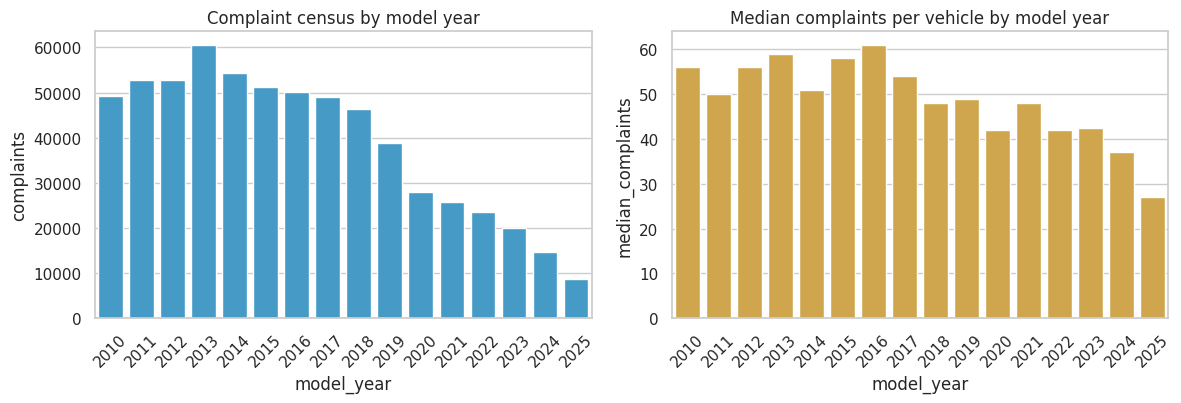

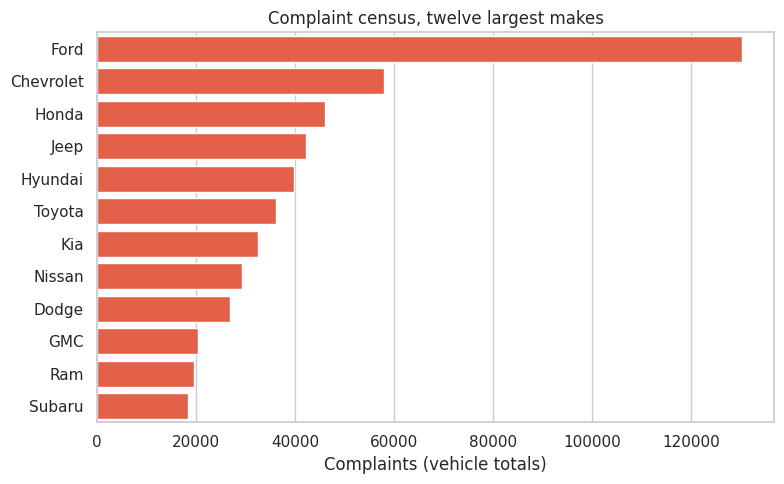

,model_year,vehicles,complaints,median_complaints
0,2010,289,"49,252",56
1,2011,295,"52,686",50
2,2012,281,"52,711",56
3,2013,293,"60,545",59
4,2014,290,"54,328",51
5,2015,281,"51,181",58
6,2016,265,"50,059",61
7,2017,269,"49,101",54
8,2018,257,"46,454",48
9,2019,247,"38,911",49


In [4]:
by_year = (
    vehicles.groupby("model_year", as_index=False)
    .agg(vehicles=("complaints", "size"), complaints=("complaints", "sum"),
         median_complaints=("complaints", "median"))
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=by_year, x="model_year", y="complaints", color="#30a2da", ax=axes[0])
axes[0].set_title("Complaint census by model year")
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(data=by_year, x="model_year", y="median_complaints", color="#e5ae38", ax=axes[1])
axes[1].set_title("Median complaints per vehicle by model year")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

make_totals = (
    vehicles.groupby("make", as_index=False)["complaints"].sum()
    .sort_values("complaints", ascending=False)
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=make_totals.head(12), y="make", x="complaints", color="#fc4f30", ax=ax,
)
ax.set_title("Complaint census, twelve largest makes")
ax.set_xlabel("Complaints (vehicle totals)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
display(by_year.style.format({"vehicles": "{:,.0f}", "complaints": "{:,.0f}", "median_complaints": "{:.0f}"}))

**Interpretation** <br>
Older model years hold more of the census: 2013 is the peak year at 60,545 complaints across 293 vehicles; 2025 is 8,771 across 171 vehicles. The median vehicle also steps down, from 56 complaints for 2010 to 27 for 2025. A 2010 model has had many more years in service than a 2025 model in a file whose bulk extract is dated 2026, so part of that slope is time in the fleet.

Ford is the largest make by a wide margin: 130,217 complaints, about one fifth of the census. Chevrolet, Honda, Jeep, and Hyundai follow.

# **4. The Vehicle, Not the Component Row:** <a id="Vehicles"></a>

Highest vehicle complaint counts


,rank,make,model,model_year,complaints,component_rows
0,1,Ford,Fusion,2010,"5,126",84
1,2,Ford,Focus,2012,"3,763",79
2,3,Hyundai,Sonata,2011,"3,374",83
3,4,Ford,F-150,2013,"2,975",88
4,5,Toyota,Prius,2010,"2,819",75
5,6,Ford,Fusion,2011,"2,783",75
6,7,Ford,Escape,2013,"2,744",88
7,8,Ford,Escape,2017,"2,663",84
8,9,Jeep,Cherokee,2014,"2,641",83
9,10,Ford,Focus,2014,"2,596",78


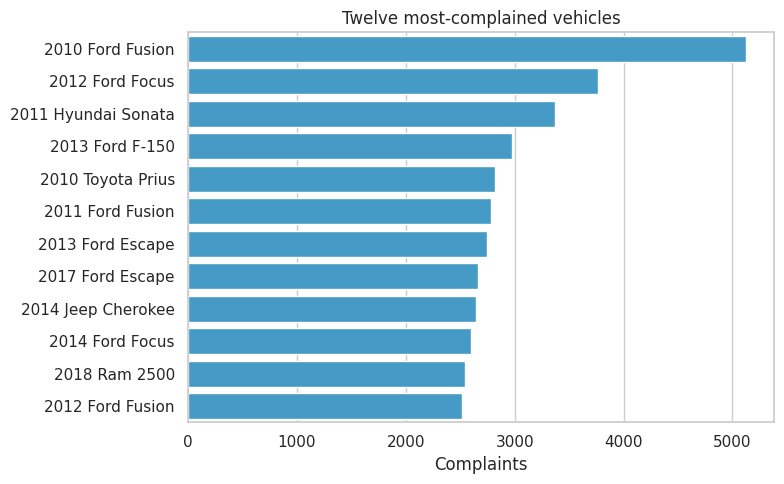

In [5]:
top_vehicles = vehicles.nlargest(12, "complaints").reset_index(drop=True)
top_vehicles.insert(0, "rank", top_vehicles.index + 1)
print("Highest vehicle complaint counts")
display(top_vehicles.style.format({"complaints": "{:,.0f}", "component_rows": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 5))
labels = top_vehicles["model_year"].astype(str) + " " + top_vehicles["make"] + " " + top_vehicles["model"]
sns.barplot(x=top_vehicles["complaints"], y=labels, color="#30a2da", ax=ax)
ax.set_title("Twelve most-complained vehicles")
ax.set_xlabel("Complaints")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretation** <br>
The top of the list is a cluster of early-2010s volume cars and one truck: 2010 Ford Fusion (5,126), 2012 Ford Focus (3,763), 2011 Hyundai Sonata (3,374), 2013 Ford F-150 (2,975), 2010 Toyota Prius (2,819). Ford occupies four of the first eight vehicles. Component-row counts on these vehicles are much smaller than the complaint total, because each row is one named part, not one complaint.

# **5. Which Components Are Named:** <a id="Components"></a>

Component mentions. Share uses the 625,987 complaint census as the denominator.


,component,complaints,share_of_complaints
156,Engine,"128,191",20.5%
63,Electrical system,"107,729",17.2%
390,Power train,"93,552",14.9%
629,Unknown or other,"80,293",12.8%
522,Steering,"64,189",10.3%
0,Air bags,"50,747",8.1%
473,Service brakes,"49,965",8.0%
342,Fuel/propulsion system,"39,237",6.3%
630,Vehicle speed control,"29,475",4.7%
553,"Structure, body","24,568",3.9%


Engine mentions: 128,191


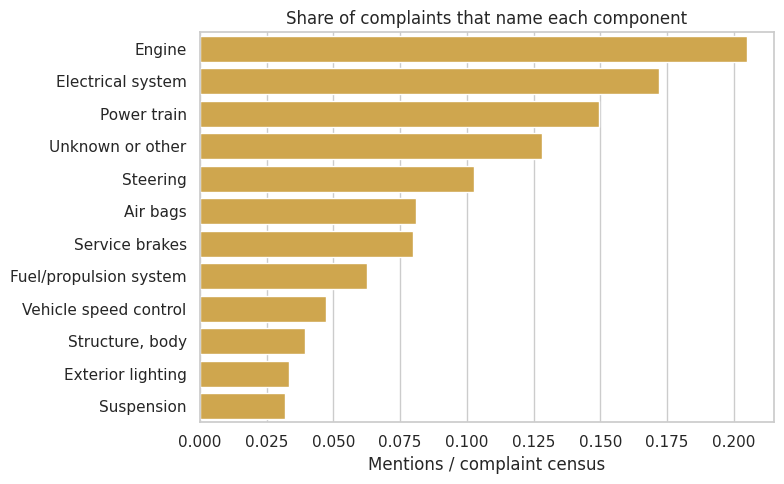

Component most often the largest mention on a vehicle:
component
Electrical system         918
Engine                    889
Air bags                  483
Power train               431
Unknown or other          339
Steering                  252
Service brakes            217
Fuel/propulsion system    107


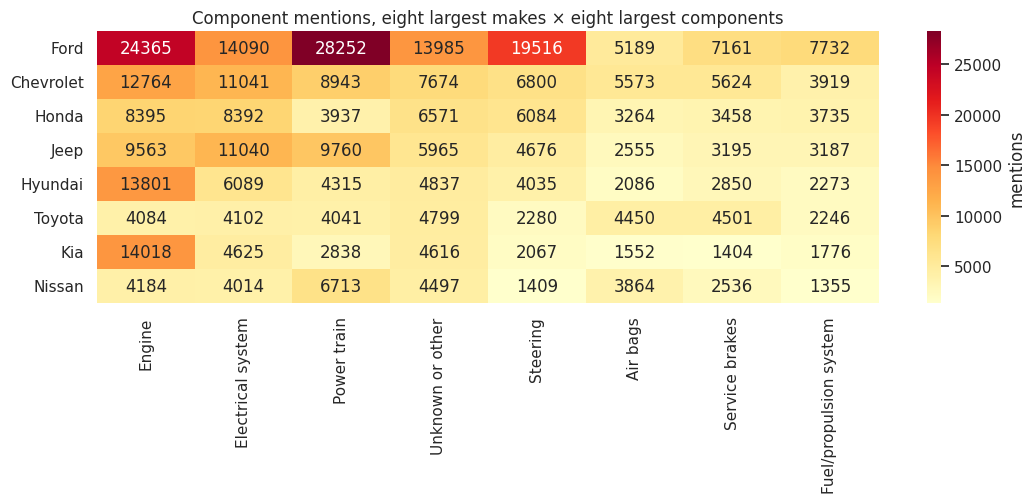

In [6]:
# Blank component labels are excluded. "Unknown or other" stays; it is a named residual.
parts = df.dropna(subset=["component"])
component_totals = (
    parts.groupby("component", as_index=False)["complaints"].sum()
    .sort_values("complaints", ascending=False)
)
component_totals["share_of_complaints"] = component_totals["complaints"] / vehicles["complaints"].sum()
print("Component mentions. Share uses the 625,987 complaint census as the denominator.")
display(
    component_totals.head(12).style.format({
        "complaints": "{:,.0f}", "share_of_complaints": "{:.1%}",
    }).background_gradient(subset=["share_of_complaints"], cmap="YlOrRd")
)
print(f"Engine mentions: {int(component_totals.loc[component_totals['component'].eq('Engine'), 'complaints'].iloc[0]):,}")

fig, ax = plt.subplots(figsize=(8, 5))
top_parts = component_totals.head(12)
sns.barplot(data=top_parts, y="component", x="share_of_complaints", color="#e5ae38", ax=ax)
ax.set_title("Share of complaints that name each component")
ax.set_xlabel("Mentions / complaint census")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Most-named component on each vehicle, by that component's mention count.
idx = parts.groupby(KEYS)["complaints"].idxmax()
lead = parts.loc[idx]
assert len(lead) == len(vehicles)
print("Component most often the largest mention on a vehicle:")
print(lead["component"].value_counts().head(8).to_string())

top_makes = make_totals.head(8)["make"].tolist()
top_comps = component_totals.head(8)["component"].tolist()
heat_src = parts.loc[parts["make"].isin(top_makes) & parts["component"].isin(top_comps)]
heat = (
    heat_src.pivot_table(index="make", columns="component", values="complaints", aggfunc="sum")
    .reindex(index=top_makes, columns=top_comps)
)
fig, ax = plt.subplots(figsize=(11, 5.2))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "mentions"})
ax.set_title("Component mentions, eight largest makes × eight largest components")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretation** <br>
Engine is named on 128,191 complaints, 20.5% of the census. Electrical system is 17.2%, power train 14.9%, and `Unknown or other` is 12.8%. Shares can sum past 100% across components because the average complaint names 1.42 components.

The component that leads a vehicle is often electrical system (918 vehicles) or engine (889). Steering leads the 2010 Fusion in the highlight file, which is a vehicle-level fact sitting on top of an engine-heavy census. Ford's engine and power-train cells are the darkest block in the make × component heatmap.

# **6. Model Year and Make:** <a id="Year"></a>

Model year vs complaints, vehicle grain: Spearman rho=-0.099, p=1.865e-10


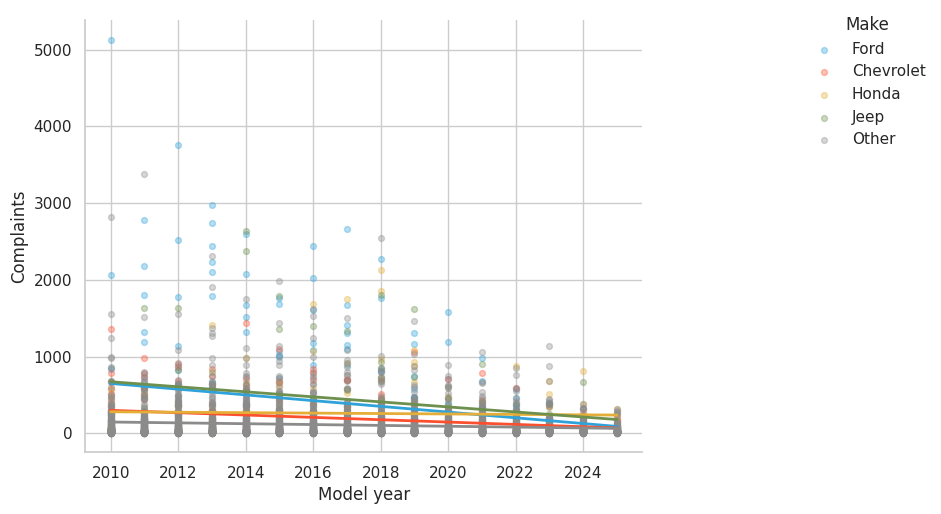

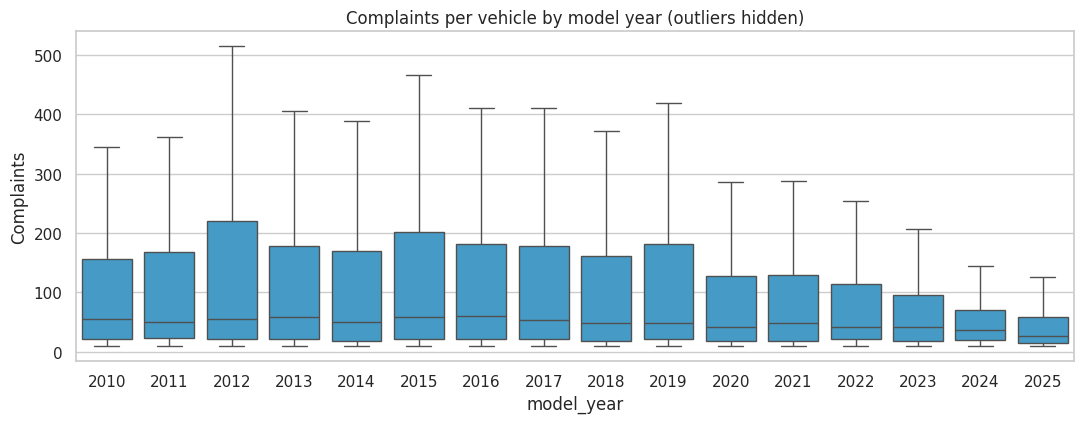

In [7]:
rho_year, p_year = stats.spearmanr(vehicles["model_year"], vehicles["complaints"])
print(f"Model year vs complaints, vehicle grain: Spearman rho={rho_year:.3f}, p={p_year:.3e}")

# Five-color hue: four largest makes, everything else collapsed, so the legend stays readable.
hue_makes = make_totals.head(4)["make"].tolist()
scatter = vehicles.copy()
scatter["make_plot"] = np.where(scatter["make"].isin(hue_makes), scatter["make"], "Other")
hue_order = hue_makes + ["Other"]
g = sns.lmplot(
    data=scatter,
    x="model_year",
    y="complaints",
    hue="make_plot",
    hue_order=hue_order,
    height=5.2,
    aspect=1.3,
    ci=None,
    scatter_kws={"alpha": 0.35, "s": 18},
    line_kws={"lw": 2},
)
g.set_axis_labels("Model year", "Complaints")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Make", frameon=False)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.4))
sns.boxplot(
    data=vehicles, x="model_year", y="complaints", color="#30a2da", ax=ax, showfliers=False,
)
ax.set_title("Complaints per vehicle by model year (outliers hidden)")
ax.set_ylabel("Complaints")
plt.tight_layout()
plt.show()

**Interpretation** <br>
At vehicle grain the rank correlation between model year and complaints is mild (Spearman ρ −0.099). The boxplots, with outliers hidden, show the median drift downward across 2010–2025. The scatter's vertical scale is set by Ford and a few other tails: those points sit far above the cloud, which is why the mean (153) is triple the median (48).

The downward year slope and the Ford tail are both visible. The model in the next section asks how much of the hold-out variation each one carries.

# **7. What Moves the Complaint Count:** <a id="Model"></a>

Hold-out R^2, model year only: 0.012
Year slope, training fit: -8.97 complaints per model year
Reference make group: Chevrolet
Hold-out R^2, model year + make group: 0.108


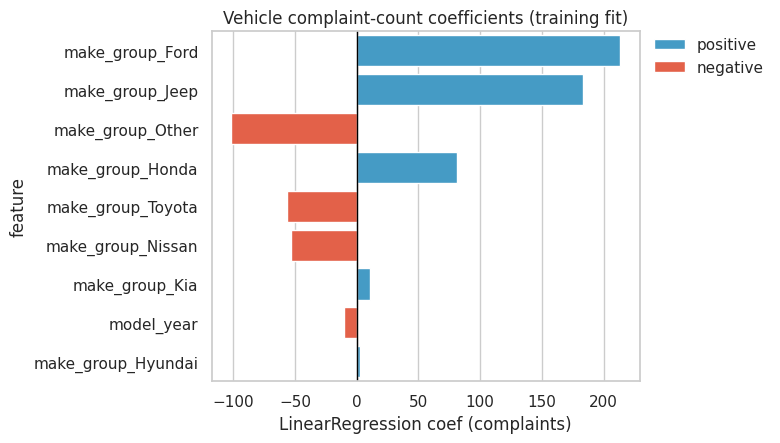

,coef
make_group_Ford,213.5
make_group_Jeep,183.0
make_group_Other,-101.7
make_group_Honda,81.6
make_group_Toyota,-56.8
make_group_Nissan,-53.5
make_group_Kia,10.7
model_year,-10.3
make_group_Hyundai,2.8


In [8]:
# Outcome is the vehicle complaint count. Make is the eight largest censuses plus Other.
# Reference level is the first sorted group, Chevrolet.
top8 = vehicles.groupby("make")["complaints"].sum().nlargest(8).index
model_df = vehicles.copy()
model_df["make_group"] = np.where(model_df["make"].isin(top8), model_df["make"], "Other")
y = model_df["complaints"]
X = model_df[["model_year", "make_group"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

year_only = LinearRegression().fit(X_train[["model_year"]], y_train)
print(f"Hold-out R^2, model year only: {r2_score(y_test, year_only.predict(X_test[['model_year']])):.3f}")
print(f"Year slope, training fit: {year_only.coef_[0]:.2f} complaints per model year")

pipe = Pipeline([
    ("pre", ColumnTransformer([
        ("num", "passthrough", ["model_year"]),
        ("cat", OneHotEncoder(drop="first"), ["make_group"]),
    ])),
    ("lr", LinearRegression()),
])
pipe.fit(X_train, y_train)
print("Reference make group:", sorted(model_df["make_group"].unique())[0])
print(f"Hold-out R^2, model year + make group: {r2_score(y_test, pipe.predict(X_test)):.3f}")

cat_names = list(pipe.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(["make_group"]))
coef = pd.Series(pipe.named_steps["lr"].coef_, index=["model_year"] + cat_names)
coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)
coef_plot = coef_sorted.rename("coef").rename_axis("feature").reset_index()
coef_plot["sign"] = np.where(coef_plot["coef"] >= 0, "positive", "negative")
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.barplot(
    data=coef_plot, x="coef", y="feature", hue="sign", dodge=False,
    palette={"positive": "#30a2da", "negative": "#fc4f30"}, ax=ax,
)
ax.axvline(0, color="black", lw=1)
park_legend(ax)
ax.set_title("Vehicle complaint-count coefficients (training fit)")
ax.set_xlabel("LinearRegression coef (complaints)")
plt.tight_layout()
plt.show()
display(coef_sorted.round(1).rename("coef").to_frame())

**Interpretation** <br>
Model year alone has hold-out R² 0.012, about −9 complaints per later model year on the training fit. Adding the make group lifts hold-out R² to 0.108.

Against Chevrolet, the reference group, Ford is about +214 complaints and Jeep about +183. Other makes as a group are about −102. A make shift of that size is an order of magnitude larger than one model year. The year slope remains about −10 complaints per year once make is in the model, which is the exposure drift, still small next to the Ford and Jeep gaps.

# **8. What It Means — Working Synthesis:** <a id="Synthesis"></a>

**What the table is:** <br>
90,254 component rows covering 4,087 make × model × model year vehicles, model years 2010–2025. `year_total` counted once is 625,987 complaints. Component mentions sum to 886,141, 1.42 mentions per complaint. The highlight file's top vehicle matches the CSV.

**Working takeaways:** <br>
- The complaint distribution is a tail. Median vehicle 48, mean 153. The top 100 vehicles are 26.7% of complaints. 2010 Ford Fusion leads at 5,126.
- Ford is 130,217 complaints. Four of the eight most-complained vehicles are Fords from 2010–2013.
- Engine is named on 20.5% of complaints, electrical system 17.2%, power train 14.9%, `Unknown or other` 12.8%.
- Model-year medians fall from 56 (2010) to 27 (2025), and 2025's census is 8,771 complaints against 2013's 60,545. Newer vehicles have had less time in service.
- Hold-out R² is 0.012 for model year alone and 0.108 for year plus make group. Ford versus Chevrolet is about +214 complaints; one model year is about −10.

**Open follow-ups:** <br>
- Rate complaints by vehicles in operation, or by years since the model year, before reading the year slope as a quality trend.
- Keep Silverado and Silverado 1500 as separate NHTSA model strings. Merging them changes the vehicle counts.